In [35]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
import seaborn as sns
import matplotlib.pylab as plt

In [ ]:
sys.path.append(os.path.abspath('..'))
from src.student_mental_health import config

In [ ]:
df = config.load_raw()

# **Define reusable functions**

In [ ]:
config.print_title('Function to identify the outliers')

def check_outliers(df, numerical_columns):
    result = defaultdict(list)
    for col in numerical_columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        result[col] = outliers
    return result
print('done')

Function to identify the outliers
done


In [85]:
config.print_title('Dunction to analyze distribution')

def analyze_target_distribution(df, target_column):
    counts = df[target_column].value_counts()
    percentages = df[target_column].value_counts(normalize=True).mul(100)

    distribution = pd.DataFrame({'Count': counts, 
                                 'Percentage': percentages })

    display(distribution)

    sns.countplot(data=df, x=target_column)
    plt.title(target_column.replace('_', ' '))
    plt.show()

    return distribution

print('Done')

Dunction to analyze distribution
Done


In [84]:
config.print_title('Function to display a Boxplot to Analyze the Distribution of a Numerical Feature Across Categories')

def show_boxplot(df, x, y):
    print('='*100)
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=x, y=y)
    plt.title(f'{x.replace('_', ' ')} vs {y.replace('_', ' ')}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    print('='*100)

print('Done')

Function to display a Boxplot to Analyze the Distribution of a Numerical Feature Across Categories
Done


In [90]:
config.print_title('Function to extract Categorical Feature Distribution Across the Target Variable (%)')

def show_target_distribution_by_category(df, col, target=config.TARGET_COLUMN):
    display(pd.crosstab( df[col], df[target], normalize='index' ).mul(100).round(2) )

print('Done')

Function to extract Categorical Feature Distribution Across the Target Variable (%)
Done


In [87]:
config.print_title('Function to display correlation Matrix Between Numerical Features')

def show_correlation_heatmap(cm, color='coolwarm', annot=True):

    plt.figure(figsize=(12, 8))

    sns.heatmap(cm, 
                annot=annot, 
                cmap=color, 
                fmt='.2f', 
                linewidths=0.5 )
    
    plt.title('Correlation Matrix Between Features')
    plt.tight_layout()
    plt.show()

print('Done')

Function to display correlation Matrix Between Numerical Features
Done


In [5]:
config.print_title('first five rows in the row dataframe')
display(df.head())

first five rows in the row dataframe


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [6]:
config.print_title('last five rows in the row dataframe')
display(df.tail())

last five rows in the row dataframe


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [7]:
config.print_title('count the missing values on each column')
display(df.isna().sum().to_frame(name='number of the missing values'))

count the missing values on each column


,number of the missing values
Student_ID,0
Age,0
Gender,0
Year_of_Study,0
Sleep_Hours,62
Study_Hours_Per_Week,0
GPA,38
Social_Media_Hours,58
Screen_Time_Hours,0
Physical_Activity,0


In [8]:
config.print_title('dataframe info')
display(df.info())

dataframe info
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate               

None

In [9]:
config.print_title('Datasframe shape')
print(f'shape         : {df.shape}')
print(f'n° of rows    : {df.shape[0]}')
print(f'n° of columns : {df.shape[1]}')

Datasframe shape
shape         : (2000, 17)
n° of rows    : 2000
n° of columns : 17


In [10]:
config.print_title("Summarize the dispersion, and shape of each analyzed column's distribution")
display(df.describe())

Summarize the dispersion, and shape of each analyzed column's distribution


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [11]:
config.print_title('Column names that include data type number ')
numerical_columns = df.select_dtypes(include='number').columns.to_list()
numerical_columns

Column names that include data type number 


['Age',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate']

In [12]:
config.print_title('Column names that include data type str ')
str_columns = df.select_dtypes(include='str').columns.to_list()
str_columns

Column names that include data type str 


['Student_ID',
 'Gender',
 'Physical_Activity',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [13]:
config.print_title('Datafram number of dimensions')
print(f'n° of dims : {df.ndim}')

Datafram number of dimensions
n° of dims : 2


In [14]:
config.print_title('Count the missing values on each column')
display(df.isna().sum().to_frame(name='number of the missing values'))

Count the missing values on each column


,number of the missing values
Student_ID,0
Age,0
Gender,0
Year_of_Study,0
Sleep_Hours,62
Study_Hours_Per_Week,0
GPA,38
Social_Media_Hours,58
Screen_Time_Hours,0
Physical_Activity,0


In [33]:
df.loc[df['Previous_Mental_Health_History']== 'Yes']['Mental_Health_Risk'].value_counts()

Mental_Health_Risk
High      294
Medium    191
Low       107
Name: count, dtype: int64

In [15]:
config.print_title('Check if there is any duplicated rows')
print(f'n° of duplicated rows : {df.duplicated().sum()}')

Check if there is any duplicated rows
n° of duplicated rows : 0


In [16]:
config.print_title('Check for inconsistencies')

for i in str_columns:
    if i != 'Student_ID':
        print(f'{i} : {[*df[i].unique()]}')

Check for inconsistencies
Gender : ['Male', 'Female', 'Non-binary']
Physical_Activity : ['Moderate', 'Low', 'High']
Part_Time_Job : ['No', 'Yes']
Diet_Quality : ['Poor', 'Average', nan, 'Good']
Previous_Mental_Health_History : ['No', 'Yes']
Mental_Health_Risk : ['High', 'Medium', 'Low']


In [67]:
config.print_title('Display Outliers sample and their count')
df_check_outliers = check_outliers(df, numerical_columns)
columns_containing_outliers = []
for k, v in df_check_outliers.items():
    if len(v) != 0:
        print(f'column : {k}')
        print(f'count : {len(v)}')
        display(df_check_outliers[k].loc[:,['Student_ID', k]].head())
        columns_containing_outliers.append(k)
        print('=' * 50)
    # print(k)

Display Outliers sample and their count
column : Age
count : 4


,Student_ID,Age
209,STU0210,29
478,STU0479,28
1615,STU1616,28
1957,STU1958,28


column : Sleep_Hours
count : 2


,Student_ID,Sleep_Hours
749,STU0750,3.6
1982,STU1983,3.3


column : Study_Hours_Per_Week
count : 7


,Student_ID,Study_Hours_Per_Week
340,STU0341,3.9
453,STU0454,3.2
519,STU0520,3.6
716,STU0717,38.3
866,STU0867,2.4


... (4 outputs left out)

column : Screen_Time_Hours
count : 7


,Student_ID,Screen_Time_Hours
268,STU0269,3.4
485,STU0486,3.8
1030,STU1031,3.8
1169,STU1170,3.3
1466,STU1467,3.8


column : Attendance_Rate
count : 12


,Student_ID,Attendance_Rate
36,STU0037,61.1
277,STU0278,62.4
523,STU0524,62.5
539,STU0540,62.8
906,STU0907,62.5


Examine the distribution of the target variable and identify any potential class imbalance.


,Count,Percentage
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


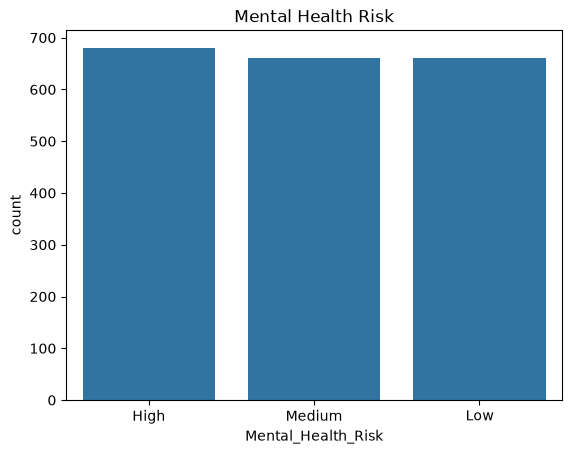

,Count,Percentage
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


In [73]:
config.print_title('Examine the distribution of the target variable and identify any potential class imbalance.')
analyze_target_distribution(df, 'Mental_Health_Risk')

In [52]:
config.print_title('Numerical Features vs Target')

numerical_features = [col for col in numerical_columns if col not in ['Student_ID', config.TARGET_COLUMN]]

display(df.groupby(config.TARGET_COLUMN)[numerical_features].mean().round(3))

Numerical Features vs Target


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Mental_Health_Risk,,,,,,,,,,
High,21.138,2.360,6.035,18.363,2.422,6.346,8.960,6.690,5.956,83.767
Low,21.112,2.895,7.524,21.700,2.718,5.763,8.257,5.244,7.088,86.332
Medium,21.144,2.642,6.729,19.981,2.552,5.922,8.416,5.895,6.528,85.192


Numerical Features Distribution by Risk Level


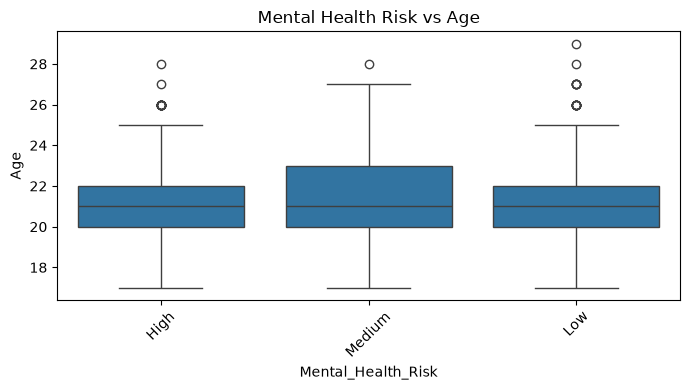

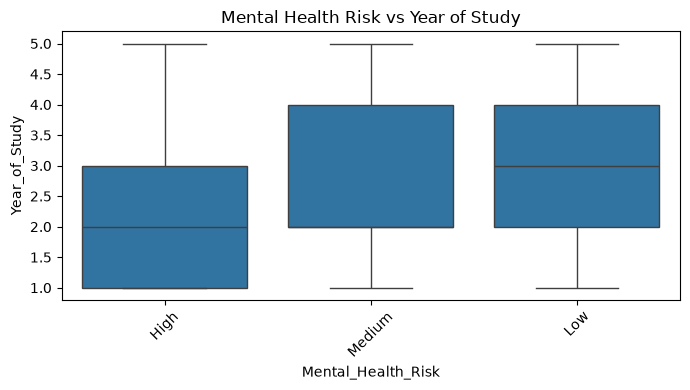

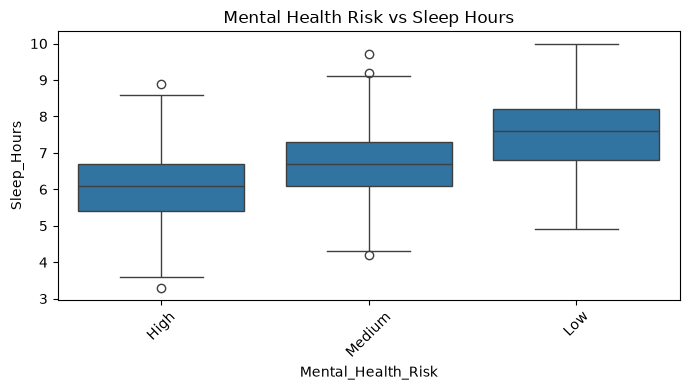

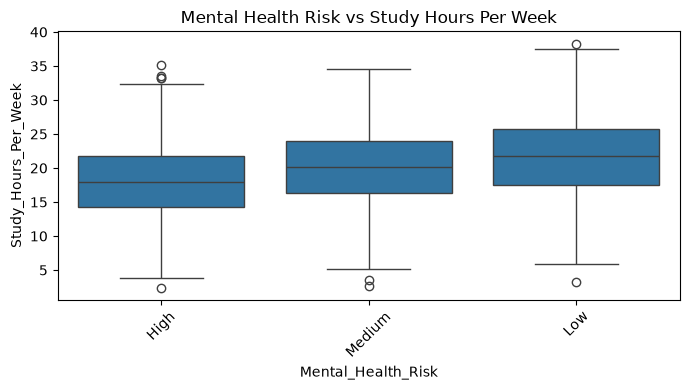

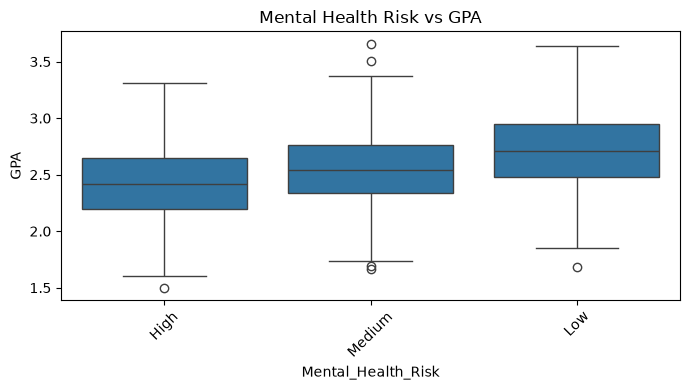

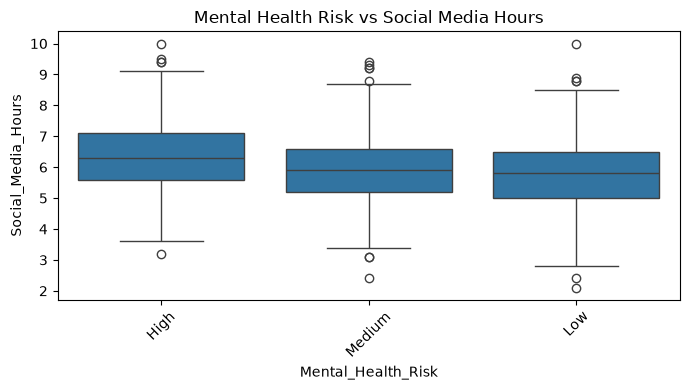

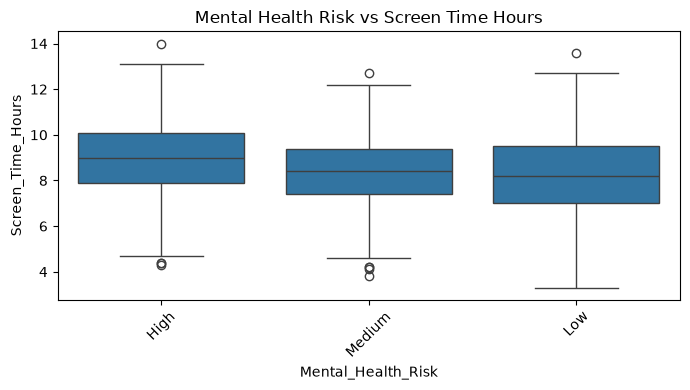

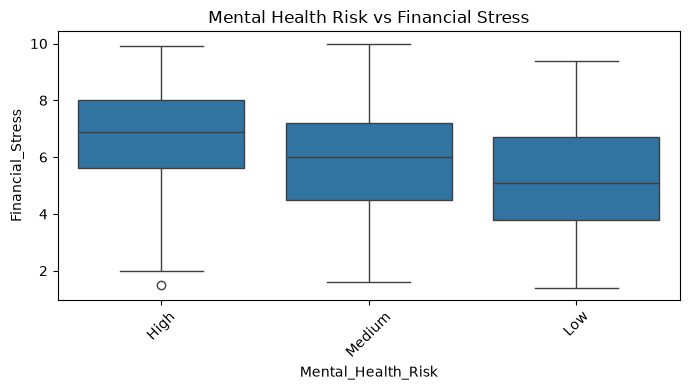

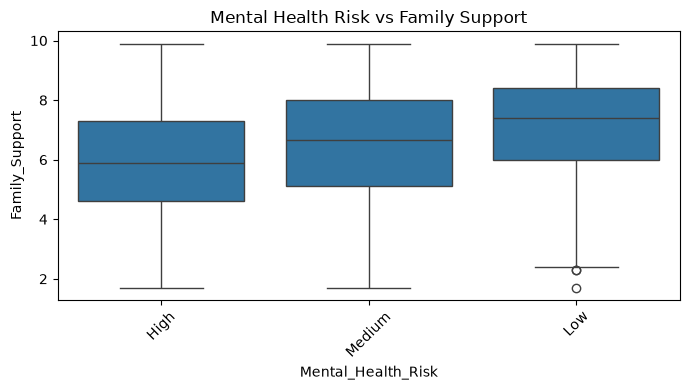

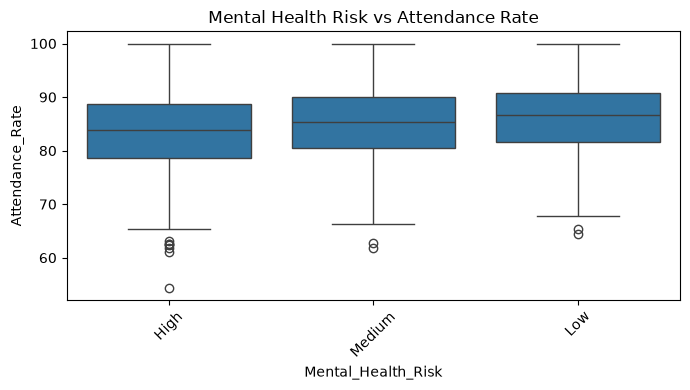

In [57]:
config.print_title('Numerical Features Distribution by Risk Level')

for col in numerical_features:
    show_boxplot(df, config.TARGET_COLUMN, col)

In [65]:
config.print_title('Categorical Features vs Target')

categorical_features = [col for col in str_columns if col not in ['Student_ID', config.TARGET_COLUMN] ]

for col in categorical_features:
    print(f'\n{col.replace('_', ' ')} vs {config.TARGET_COLUMN.replace('_', ' ')}')
    show_target_distribution_by_category(df, col)
    print("=" * 50)

Categorical Features vs Target

Gender vs Mental Health Risk


Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.60,33.47,31.93
Male,33.37,31.76,34.87
Non-binary,34.02,40.21,25.77



Physical Activity vs Mental Health Risk


Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,20.24,49.40,30.36
Low,45.95,22.83,31.22
Moderate,31.35,33.11,35.54



Part Time Job vs Mental Health Risk


Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,30.26,36.23,33.51
Yes,40.79,27.14,32.07



Diet Quality vs Mental Health Risk


Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,32.33,33.49,34.19
Good,27.48,42.77,29.75
Poor,42.25,24.02,33.73



Previous Mental Health History vs Mental Health Risk


Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.41,39.28,33.31
Yes,49.66,18.07,32.26


In [77]:
correlation_matrix = df[numerical_features].corr()

display(correlation_matrix)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Age,1.000000,0.002186,-0.010572,-0.007476,0.001437,-0.007609,-0.005439,0.004142,-0.010363,-0.009612
Year_of_Study,0.002186,1.000000,0.025545,0.703401,0.344012,-0.353989,-0.239093,-0.013438,0.008983,0.078682
Sleep_Hours,-0.010572,0.025545,1.000000,0.032237,0.246255,0.002183,0.019314,0.024435,0.009997,0.076609
Study_Hours_Per_Week,-0.007476,0.703401,0.032237,1.000000,0.492501,-0.501178,-0.333568,-0.025538,0.041464,0.138003
GPA,0.001437,0.344012,0.246255,0.492501,1.000000,-0.225998,-0.158174,0.002308,0.012862,0.285952
Social_Media_Hours,-0.007609,-0.353989,0.002183,-0.501178,-0.225998,1.000000,0.681404,-0.006319,-0.058921,-0.067095
Screen_Time_Hours,-0.005439,-0.239093,0.019314,-0.333568,-0.158174,0.681404,1.000000,-0.003091,-0.044414,-0.061941
Financial_Stress,0.004142,-0.013438,0.024435,-0.025538,0.002308,-0.006319,-0.003091,1.000000,0.046326,-0.000887
Family_Support,-0.010363,0.008983,0.009997,0.041464,0.012862,-0.058921,-0.044414,0.046326,1.000000,0.001640
Attendance_Rate,-0.009612,0.078682,0.076609,0.138003,0.285952,-0.067095,-0.061941,-0.000887,0.001640,1.000000


Correlation Matrix Between Numerical Features


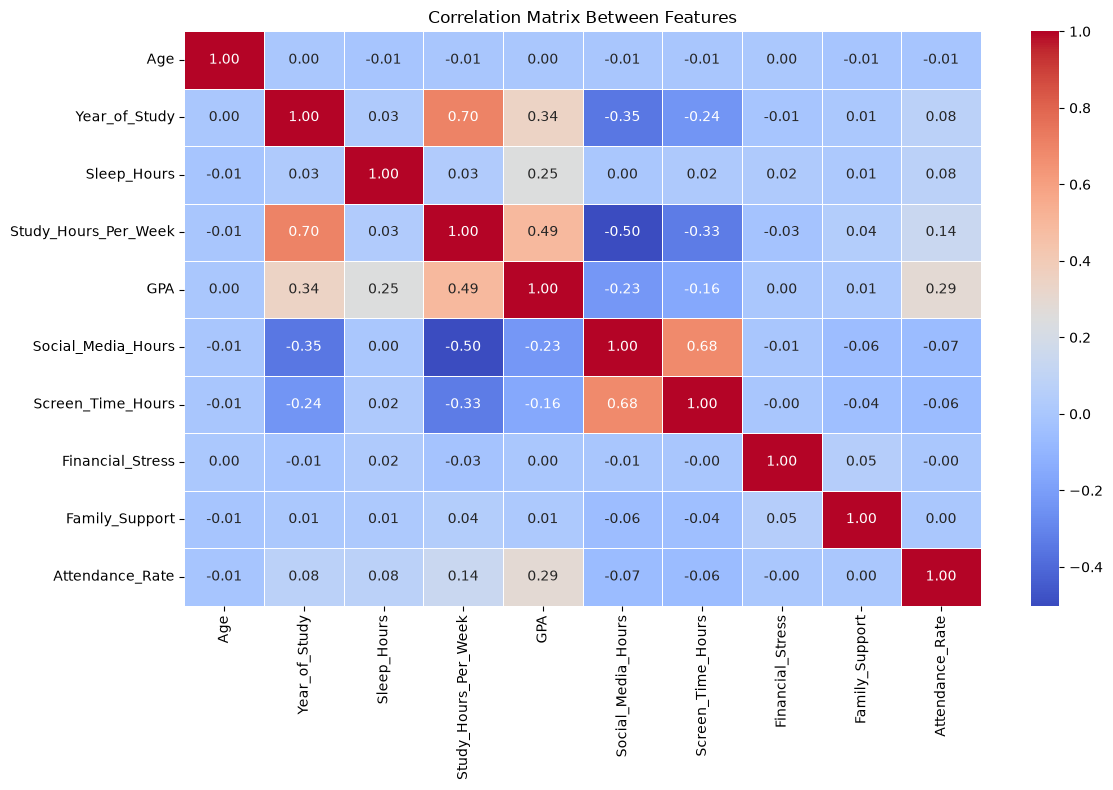

In [83]:
config.print_title('Correlation Matrix Between Numerical Features')

show_correlation_heatmap(correlation_matrix)